## Random Forest

### 1. Import libraries

In [1]:
import glob

import numpy as np
import pandas as pandas
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, PredefinedSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.base import clone
from sklearn.feature_selection import VarianceThreshold

#### 2. Data preprocessing

##### 2a. Import CSV files and combine into one dataframe

In [2]:
csv_folder = "../data/raw_data/*.csv"
file_paths = glob.glob(csv_folder)

print(f"Found {len(file_paths)} files")

dataframe_list = [pandas.read_csv(file) for file in file_paths]
dataframe_combined = pandas.concat(dataframe_list, ignore_index=True)
dataframe_combined = dataframe_combined.reset_index(drop=True)

Found 15 files


##### 2b. Overview of data

In [ ]:
dataframe_combined.shape

In [ ]:
dataframe_combined.head()

In [ ]:
dataframe_combined.info()

In [3]:
dataframe_combined["Attack Name"].value_counts()

Attack Name
DoS TCP Flood               2106916
Recon Port Scan              485522
MQTT DDoS Publish Flood      413913
MQTT DoS Connect Flood       238031
Recon OS Scan                 85317
Benign Traffic                32620
Recon Vulnerability Scan       8321
DoS UDP Flood                  3115
DDoS UDP Flood                 2576
DDoS ICMP Flood                2552
MQTT Malformed                 2246
DoS ICMP Flood                 2107
MITM ARP Spoofing              1053
MQTT DoS Publish Flood          953
Recon Ping Sweep                 71
Name: count, dtype: int64

##### 2c. Drop Recon Ping Sweep due to its extremely low sample size

In [3]:
dataframe_combined = dataframe_combined[~dataframe_combined['Attack Name'].isin(['Recon Ping Sweep', 'MITM ARP Spoofing'])].copy()

##### 2c. Replace spaces in columns with "_"

In [4]:
dataframe_combined.columns = dataframe_combined.columns.str.replace(" ", "_")
dataframe_combined.columns.to_list()

['Flow_ID',
 'Src_IP',
 'Src_Port',
 'Dst_IP',
 'Dst_Port',
 'Protocol',
 'Timestamp',
 'Flow_Duration',
 'Total_Fwd_Packet',
 'Total_Bwd_packets',
 'Total_Length_of_Fwd_Packet',
 'Total_Length_of_Bwd_Packet',
 'Fwd_Packet_Length_Max',
 'Fwd_Packet_Length_Min',
 'Fwd_Packet_Length_Mean',
 'Fwd_Packet_Length_Std',
 'Bwd_Packet_Length_Max',
 'Bwd_Packet_Length_Min',
 'Bwd_Packet_Length_Mean',
 'Bwd_Packet_Length_Std',
 'Flow_Bytes/s',
 'Flow_Packets/s',
 'Flow_IAT_Mean',
 'Flow_IAT_Std',
 'Flow_IAT_Max',
 'Flow_IAT_Min',
 'Fwd_IAT_Total',
 'Fwd_IAT_Mean',
 'Fwd_IAT_Std',
 'Fwd_IAT_Max',
 'Fwd_IAT_Min',
 'Bwd_IAT_Total',
 'Bwd_IAT_Mean',
 'Bwd_IAT_Std',
 'Bwd_IAT_Max',
 'Bwd_IAT_Min',
 'Fwd_PSH_Flags',
 'Bwd_PSH_Flags',
 'Fwd_URG_Flags',
 'Bwd_URG_Flags',
 'Fwd_Header_Length',
 'Bwd_Header_Length',
 'Fwd_Packets/s',
 'Bwd_Packets/s',
 'Packet_Length_Min',
 'Packet_Length_Max',
 'Packet_Length_Mean',
 'Packet_Length_Std',
 'Packet_Length_Variance',
 'FIN_Flag_Count',
 'SYN_Flag_Count',
 'R

##### 2d. Drop problematic columns

In [5]:
dataframe_combined = dataframe_combined.drop(columns=["Flow_ID", "Src_IP", "Src_Port", "Dst_IP", "Dst_Port", "Protocol", "Timestamp", "Label"])
dataframe_combined.columns.to_list()

['Flow_Duration',
 'Total_Fwd_Packet',
 'Total_Bwd_packets',
 'Total_Length_of_Fwd_Packet',
 'Total_Length_of_Bwd_Packet',
 'Fwd_Packet_Length_Max',
 'Fwd_Packet_Length_Min',
 'Fwd_Packet_Length_Mean',
 'Fwd_Packet_Length_Std',
 'Bwd_Packet_Length_Max',
 'Bwd_Packet_Length_Min',
 'Bwd_Packet_Length_Mean',
 'Bwd_Packet_Length_Std',
 'Flow_Bytes/s',
 'Flow_Packets/s',
 'Flow_IAT_Mean',
 'Flow_IAT_Std',
 'Flow_IAT_Max',
 'Flow_IAT_Min',
 'Fwd_IAT_Total',
 'Fwd_IAT_Mean',
 'Fwd_IAT_Std',
 'Fwd_IAT_Max',
 'Fwd_IAT_Min',
 'Bwd_IAT_Total',
 'Bwd_IAT_Mean',
 'Bwd_IAT_Std',
 'Bwd_IAT_Max',
 'Bwd_IAT_Min',
 'Fwd_PSH_Flags',
 'Bwd_PSH_Flags',
 'Fwd_URG_Flags',
 'Bwd_URG_Flags',
 'Fwd_Header_Length',
 'Bwd_Header_Length',
 'Fwd_Packets/s',
 'Bwd_Packets/s',
 'Packet_Length_Min',
 'Packet_Length_Max',
 'Packet_Length_Mean',
 'Packet_Length_Std',
 'Packet_Length_Variance',
 'FIN_Flag_Count',
 'SYN_Flag_Count',
 'RST_Flag_Count',
 'PSH_Flag_Count',
 'ACK_Flag_Count',
 'URG_Flag_Count',
 'CWR_Flag_Cou

##### 2f. Drop rows with null values (currently unnecessary as no rows have null values)

In [6]:
dataframe_combined.dropna()

,Flow_Duration,Total_Fwd_Packet,Total_Bwd_packets,Total_Length_of_Fwd_Packet,Total_Length_of_Bwd_Packet,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Max,...,Fwd_Seg_Size_Min,Active_Mean,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,Attack_Name
0,14746364,6,0,63.0,0.0,39.0,0.0,10.500000,16.944025,0.0,...,32,0.0,0.0,0.0,0.0,14681116.0,0.000000,14681116.0,14681116.0,Benign Traffic
1,60102110,18,0,4135.0,0.0,1408.0,0.0,229.722222,490.460505,0.0,...,32,219123.0,0.0,219123.0,219123.0,14957706.0,190543.248665,15061923.0,14672051.0,Benign Traffic
2,90106769,9,0,1164.0,0.0,194.0,0.0,129.333333,97.000000,0.0,...,32,582529.0,0.0,582529.0,582529.0,29841412.0,319090.538141,30049066.0,29473997.0,Benign Traffic
3,119998980,123,123,2157.0,4.0,20.0,0.0,17.536585,2.309257,2.0,...,32,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic
4,119998539,123,123,5411.0,4.0,46.0,0.0,43.991870,5.699433,2.0,...,32,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3385308,0,2,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood
3385309,1552,2,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood
3385310,22717,2,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood
3385311,0,2,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood


### 3. Prepare data for model training

##### 3a. Sample smaller subset

In [7]:
def sample_or_take_all(group):
    sample_size = min(len(group), 6000)
    return group.sample(n=sample_size, random_state=42)

small_df = dataframe_combined.groupby('Attack_Name').apply(sample_or_take_all)
small_df = small_df.reset_index(level=0)

In [8]:
small_df.info()

<class 'pandas.DataFrame'>
Index: 55549 entries, 6528 to 2730772
Data columns (total 77 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Attack_Name                 55549 non-null  str    
 1   Flow_Duration               55549 non-null  int64  
 2   Total_Fwd_Packet            55549 non-null  int64  
 3   Total_Bwd_packets           55549 non-null  int64  
 4   Total_Length_of_Fwd_Packet  55549 non-null  float64
 5   Total_Length_of_Bwd_Packet  55549 non-null  float64
 6   Fwd_Packet_Length_Max       55549 non-null  float64
 7   Fwd_Packet_Length_Min       55549 non-null  float64
 8   Fwd_Packet_Length_Mean      55549 non-null  float64
 9   Fwd_Packet_Length_Std       55549 non-null  float64
 10  Bwd_Packet_Length_Max       55549 non-null  float64
 11  Bwd_Packet_Length_Min       55549 non-null  float64
 12  Bwd_Packet_Length_Mean      55549 non-null  float64
 13  Bwd_Packet_Length_Std       55549 non-null

##### 3b. Shuffle samples

In [9]:
small_df_rnd = small_df.sample(frac=1, random_state=42)
small_df_rnd = small_df_rnd.reset_index(drop=True)

In [142]:
small_df_rnd.info()

<class 'pandas.DataFrame'>
RangeIndex: 55549 entries, 0 to 55548
Data columns (total 77 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Attack_Name                 55549 non-null  str    
 1   Flow_Duration               55549 non-null  int64  
 2   Total_Fwd_Packet            55549 non-null  int64  
 3   Total_Bwd_packets           55549 non-null  int64  
 4   Total_Length_of_Fwd_Packet  55549 non-null  float64
 5   Total_Length_of_Bwd_Packet  55549 non-null  float64
 6   Fwd_Packet_Length_Max       55549 non-null  float64
 7   Fwd_Packet_Length_Min       55549 non-null  float64
 8   Fwd_Packet_Length_Mean      55549 non-null  float64
 9   Fwd_Packet_Length_Std       55549 non-null  float64
 10  Bwd_Packet_Length_Max       55549 non-null  float64
 11  Bwd_Packet_Length_Min       55549 non-null  float64
 12  Bwd_Packet_Length_Mean      55549 non-null  float64
 13  Bwd_Packet_Length_Std       55549 non-null

##### 3c. Separate targets and features

In [10]:
features = small_df_rnd.drop(columns=['Attack_Name'])
targets = small_df_rnd['Attack_Name']

In [11]:
targets.head

<bound method NDFrame.head of 0                 Recon Port Scan
1          MQTT DoS Connect Flood
2                   DoS UDP Flood
3          MQTT DoS Connect Flood
4                  DoS ICMP Flood
                   ...           
55544             Recon Port Scan
55545    Recon Vulnerability Scan
55546               Recon OS Scan
55547              Benign Traffic
55548               DoS TCP Flood
Name: Attack_Name, Length: 55549, dtype: str>

##### 3d. Create scaler pipeline

In [124]:
# scaler = StandardScaler()
# scaler.fit_transform(features)

scaler_pipeline = Pipeline(steps=["scaler", StandardScaler()])

### 4. Split data into training and test

In [11]:
features_train, features_test, targets_train, targets_test = train_test_split(features, targets, test_size=0.2, random_state=12, shuffle=True)

##### 4b. SMOTEN

In [12]:
features_train.shape

(44439, 76)

In [13]:
from imblearn.over_sampling import RandomOverSampler, SMOTE

smoten = SMOTE()
features_train, targets_train = smoten.fit_resample(features_train, targets_train)

In [14]:
features_train.shape

(62855, 76)

##### 5a. Create helper evaluate functions

In [15]:
def evaluate(model, features_data, targets_data):
    prediction = model.predict(features_data)
    return {
        "Accuracy": accuracy_score(targets_data, prediction),
        "Precision": precision_score(targets_data, prediction, average="weighted", zero_division=0),
        "Recall": recall_score(targets_data, prediction, average="weighted", zero_division=0),
        "F1": f1_score(targets_data, prediction, average="weighted", zero_division=0),
        "F1_macro": f1_score(targets_data, prediction, average="macro", zero_division=0),
    }

def evaluate_class_report(model, features_data, targets_data):
    prediction = model.predict(features_data)

    return classification_report(targets_data, prediction, output_dict=True, zero_division=0)



def plot_confusion_matrix(model, features_data, targets_data, title="Confusion Matrix"):
    prediction = model.predict(features_data)
    cm = confusion_matrix(targets_data, prediction)

    fig, ax = plt.subplots(figsize=(10,10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

    display.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', values_format="d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return cm

def plot_confusion_matrix_norm(model, features_data, targets_data, title="Confusion Matrix"):
    prediction = model.predict(features_data)
    cm_normalized = confusion_matrix(targets_data, prediction, normalize='true')

    fig, ax = plt.subplots(figsize=(10,10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=model.classes_)

    display.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', values_format=".2f")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return cm_normalized

##### 5b. Split for validation and gridsearchcv

In [16]:
# split for hold-out validation
X_train, X_val, Y_train, Y_val = train_test_split(features_train, targets_train, test_size=0.2, random_state=7, shuffle=True)

# split for GridSearchCV, stratify=Y_train maintains class proportions
X_train_param, X_val_param, Y_train_param, Y_val_param = train_test_split(X_train, Y_train, test_size=0.2, random_state=7, shuffle=True, stratify=Y_train)

##### 5c. Set parameter grid

In [17]:
param_grid = {
    "classifier__n_estimators": [100],
    "classifier__max_depth": [64, None],
    "classifier__min_samples_split": [2],
    "classifier__min_samples_leaf": [1],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": ["balanced"]
}

scoring_param = {
    "accuracy": "accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro"
}

##### 5d. Combine train and val data for PredefinedSplit

In [18]:
X_combined = pandas.concat([X_train_param, X_val_param])
Y_combined = pandas.concat([Y_train_param, Y_val_param])

XY_fold = np.concatenate([
    np.full(len(X_train_param), -1),
    np.zeros(len(X_val_param))
])

holdout_cv = PredefinedSplit(XY_fold)

##### 5e. Create a raw model

In [19]:
model_holdout = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier())
])

##### 5f. GridSearchCV

In [20]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)


grid_search = GridSearchCV(
    estimator=model_holdout,
    param_grid=param_grid,
    scoring=scoring_param,
    cv=holdout_cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit="f1_macro"
)

##### 5g. Run grid search

In [21]:
grid_search.fit(X_combined, Y_combined)

print("Best Parameters:")
print(grid_search.best_params_)
print("Best Validation Macro F1:")
print(grid_search.best_score_)

Fitting 1 folds for each of 4 candidates, totalling 4 fits
Best Parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Best Validation Macro F1:
0.8703133306546207


##### 5h. Report all parameter combinations

In [22]:
grid_results = pandas.DataFrame(grid_search.cv_results_)

grid_results[
    [
        "rank_test_f1_macro",
        "mean_train_f1_macro",
        "mean_test_f1_macro",
        "mean_test_f1_weighted",
        "mean_test_accuracy",
        "mean_test_precision_weighted",
        "mean_test_recall_weighted",
        "params"
    ]
].sort_values("rank_test_f1_macro").head(10)

,rank_test_f1_macro,mean_train_f1_macro,mean_test_f1_macro,mean_test_f1_weighted,mean_test_accuracy,mean_test_precision_weighted,mean_test_recall_weighted,params
2,1,0.975617,0.870313,0.870086,0.870737,0.874424,0.870737,"{'classifier__class_weight': 'balanced', 'clas..."
0,2,0.973717,0.869833,0.869614,0.870439,0.874830,0.870439,"{'classifier__class_weight': 'balanced', 'clas..."
3,3,0.973564,0.866792,0.866557,0.867356,0.872091,0.867356,"{'classifier__class_weight': 'balanced', 'clas..."
1,4,0.974732,0.866717,0.866476,0.867157,0.871508,0.867157,"{'classifier__class_weight': 'balanced', 'clas..."


### 6. Training Model - Hold-out Validation

##### 6a. Train and evaluate model using fit() and predict()

In [23]:
best_model = clone(model_holdout).set_params(**grid_search.best_params_)

best_model.fit(X_train, Y_train)

holdout_scores = pandas.DataFrame({
    "Train": evaluate(best_model, X_train, Y_train),
    "Validation": evaluate(best_model, X_val, Y_val),
}).T
holdout_scores

,Accuracy,Precision,Recall,F1,F1_macro
Train,0.974584,0.977991,0.974584,0.974189,0.974244
Validation,0.883303,0.886776,0.883303,0.882794,0.881794


##### 6b. Classification Reports

In [24]:
holdout_report_train = pandas.DataFrame(evaluate_class_report(best_model, X_train, Y_train)).T
holdout_report_train

,precision,recall,f1-score,support
Benign Traffic,0.999476,0.996343,0.997907,3828.000000
DDoS ICMP Flood,1.000000,0.999485,0.999742,3882.000000
DDoS UDP Flood,1.000000,0.999226,0.999613,3874.000000
DoS ICMP Flood,0.995907,0.998974,0.997438,3897.000000
DoS TCP Flood,1.000000,1.000000,1.000000,3838.000000
DoS UDP Flood,0.999743,0.995647,0.997691,3905.000000
MQTT DDoS Publish Flood,0.995907,0.999487,0.997693,3895.000000
MQTT DoS Connect Flood,0.991712,0.997135,0.994416,3840.000000
MQTT DoS Publish Flood,1.000000,1.000000,1.000000,3848.000000
MQTT Malformed,0.999487,0.996932,0.998208,3911.000000


In [25]:
holdout_report_val = pandas.DataFrame(evaluate_class_report(best_model, X_val, Y_val)).T
holdout_report_val

,precision,recall,f1-score,support
Benign Traffic,0.825103,0.796425,0.810510,1007.000000
DDoS ICMP Flood,0.805000,0.844701,0.824373,953.000000
DDoS UDP Flood,0.801053,0.791883,0.796442,961.000000
DoS ICMP Flood,0.851197,0.872068,0.861506,938.000000
DoS TCP Flood,1.000000,0.997994,0.998996,997.000000
DoS UDP Flood,0.762567,0.766667,0.764611,930.000000
MQTT DDoS Publish Flood,0.943557,0.942553,0.943055,940.000000
MQTT DoS Connect Flood,0.954865,0.956784,0.955823,995.000000
MQTT DoS Publish Flood,0.992864,0.986829,0.989837,987.000000
MQTT Malformed,0.966631,0.971861,0.969239,924.000000


In [26]:
print(holdout_report_val)

                          precision    recall  f1-score       support
Benign Traffic             0.825103  0.796425  0.810510   1007.000000
DDoS ICMP Flood            0.805000  0.844701  0.824373    953.000000
DDoS UDP Flood             0.801053  0.791883  0.796442    961.000000
DoS ICMP Flood             0.851197  0.872068  0.861506    938.000000
DoS TCP Flood              1.000000  0.997994  0.998996    997.000000
DoS UDP Flood              0.762567  0.766667  0.764611    930.000000
MQTT DDoS Publish Flood    0.943557  0.942553  0.943055    940.000000
MQTT DoS Connect Flood     0.954865  0.956784  0.955823    995.000000
MQTT DoS Publish Flood     0.992864  0.986829  0.989837    987.000000
MQTT Malformed             0.966631  0.971861  0.969239    924.000000
Recon OS Scan              0.739059  0.910478  0.815861    983.000000
Recon Port Scan            0.916053  0.665241  0.770756    935.000000
Recon Vulnerability Scan   0.961840  0.962782  0.962310   1021.000000
accuracy            

##### 6c. Confusion Matrices

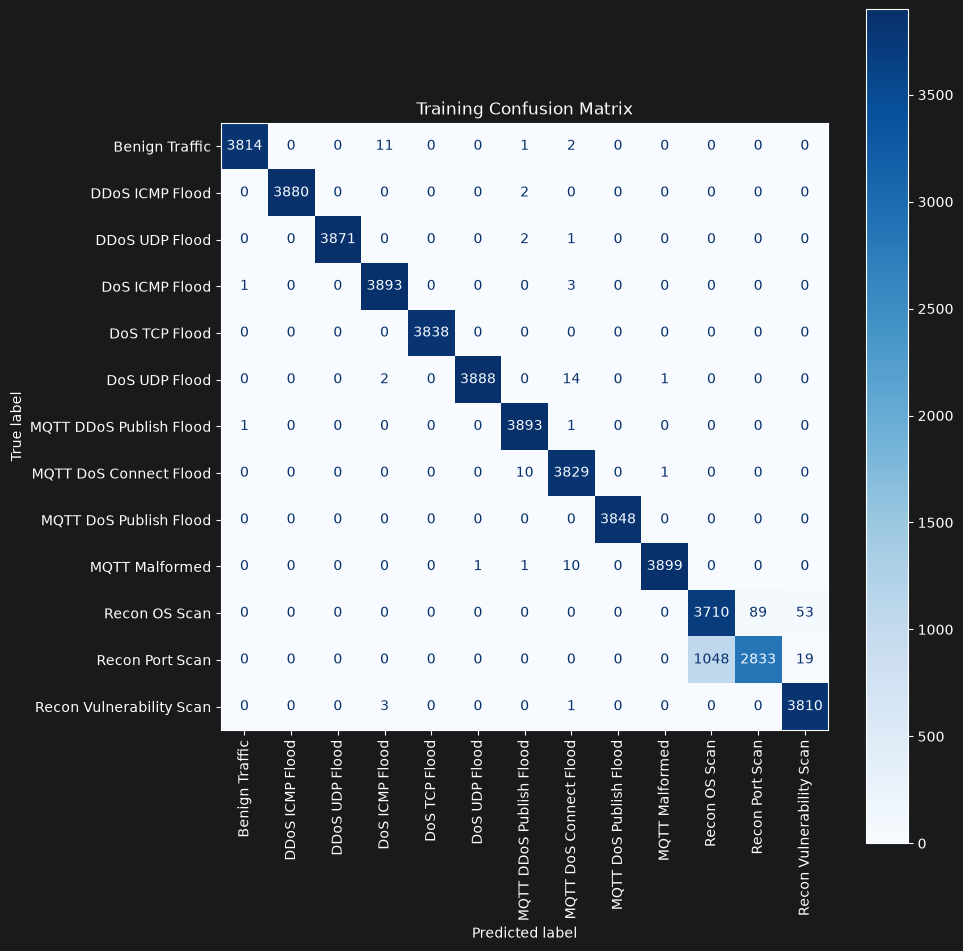

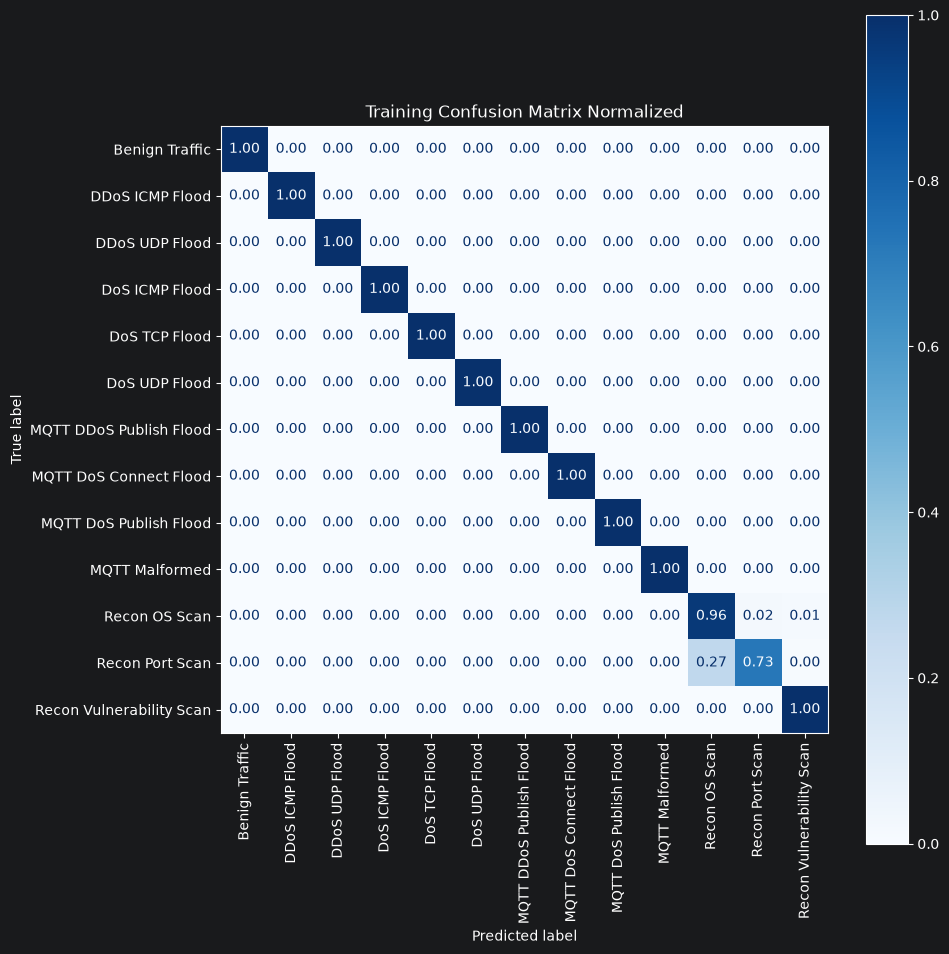

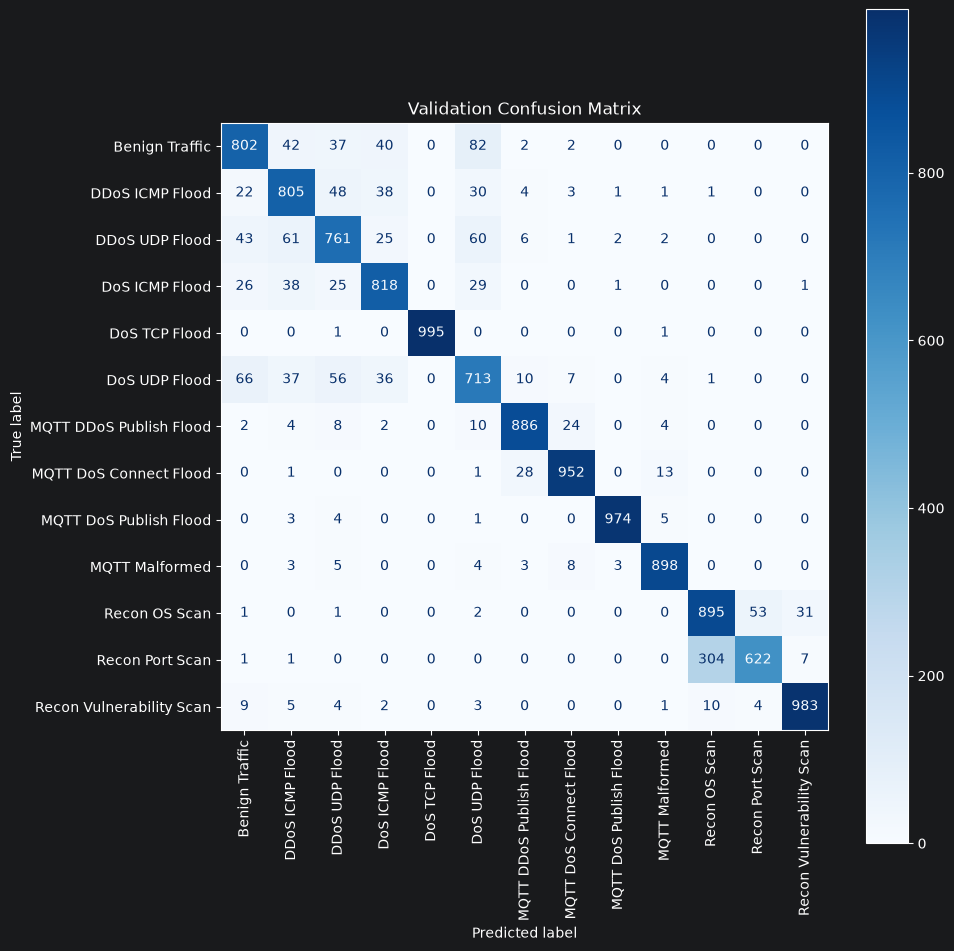

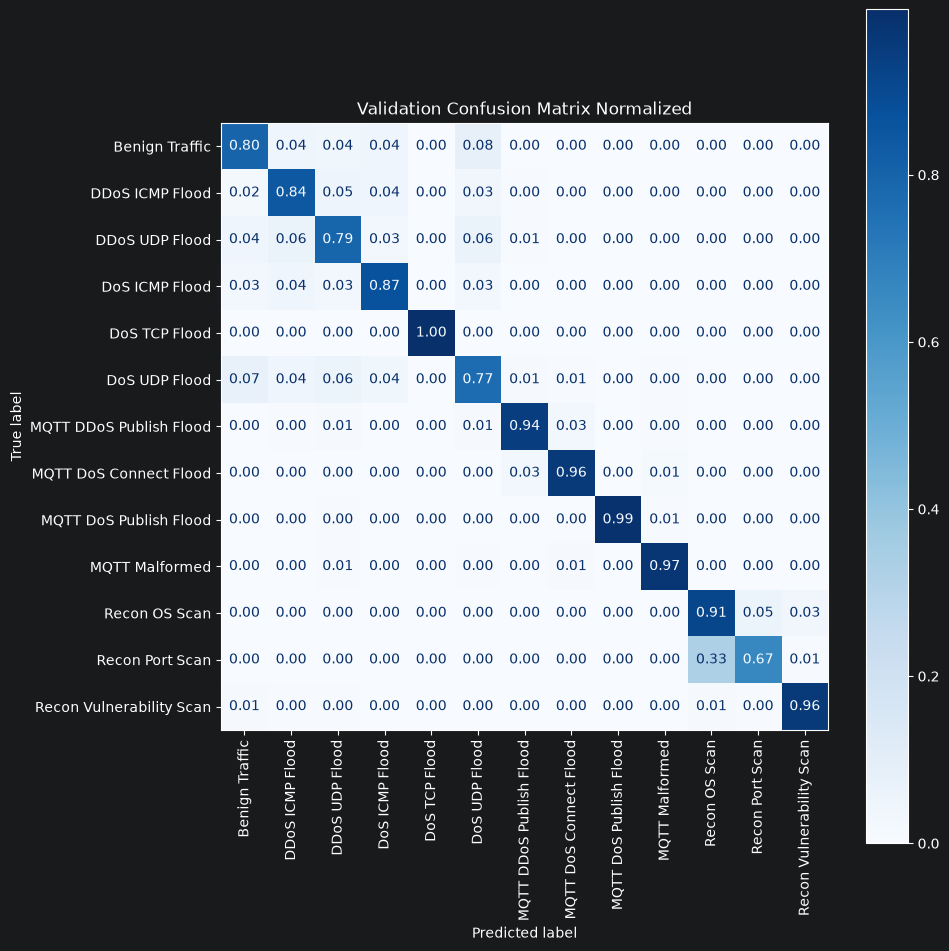

In [27]:
train_cm = plot_confusion_matrix(
    best_model,
    X_train,
    Y_train,
    title="Training Confusion Matrix"
)

train_cm_norm = plot_confusion_matrix_norm(
    best_model,
    X_train,
    Y_train,
    title="Training Confusion Matrix Normalized"
)

val_cm = plot_confusion_matrix(
    best_model,
    X_val,
    Y_val,
    title="Validation Confusion Matrix"
)

val_cm_norm = plot_confusion_matrix_norm(
    best_model,
    X_val,
    Y_val,
    title="Validation Confusion Matrix Normalized"
)

### 7. Model Training - Stratified K-fold Cross-validation

##### 7a. Set up Stratified K-fold validation

In [28]:
k = 10
strat_kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

model_cv = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier())
])

scoring = {
    "accuracy": "accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro",
}

best_model_cv = clone(model_cv).set_params(**grid_search.best_params_)

cv_results = cross_validate(
    best_model_cv,
    X_train,
    Y_train,
    cv=strat_kfold,
    scoring=scoring,
    return_train_score=True
)

##### 7b. Dataframe stores fold results

In [29]:
fold_results = pandas.DataFrame({
    name: cv_results[f"{split}_{metric}"]
    for metric in scoring
    for split, name in [
        ("train", f"Train {metric}"),
        ("test", f"Test {metric}")
    ]
})

fold_results.index = range(1, k + 1)
fold_results.index.name = "Fold"

fold_results.round(4)

,Train accuracy,Test accuracy,Train precision_weighted,Test precision_weighted,Train recall_weighted,Test recall_weighted,Train f1_weighted,Test f1_weighted,Train f1_macro,Test f1_macro
Fold,,,,,,,,,,
1,0.9745,0.8735,0.9782,0.8772,0.9745,0.8735,0.9741,0.8730,0.9742,0.8732
2,0.9733,0.8719,0.9776,0.8756,0.9733,0.8719,0.9727,0.8713,0.9728,0.8715
3,0.9746,0.8805,0.9782,0.8840,0.9746,0.8805,0.9742,0.8798,0.9743,0.8800
4,0.9742,0.8795,0.9782,0.8832,0.9742,0.8795,0.9737,0.8792,0.9738,0.8794
5,0.9741,0.8807,0.9780,0.8850,0.9741,0.8807,0.9737,0.8803,0.9737,0.8804
6,0.9743,0.8767,0.9783,0.8813,0.9743,0.8767,0.9738,0.8760,0.9739,0.8762
7,0.9731,0.8833,0.9775,0.8868,0.9731,0.8833,0.9725,0.8826,0.9726,0.8828
8,0.9740,0.8783,0.9782,0.8824,0.9740,0.8783,0.9735,0.8778,0.9736,0.8780
9,0.9734,0.8833,0.9777,0.8875,0.9734,0.8833,0.9729,0.8823,0.9730,0.8826


##### 7c. Dataframe for summarizing results

In [30]:
cv_scores = pandas.DataFrame({
    metric: {
        "Mean": cv_results[f"test_{metric}"].mean(),
        "Std": cv_results[f"test_{metric}"].std()
    }
    for metric in scoring
}).T
cv_scores.round(4)

,Mean,Std
accuracy,0.8791,0.0038
precision_weighted,0.8830,0.0038
recall_weighted,0.8791,0.0038
f1_weighted,0.8785,0.0038
f1_macro,0.8787,0.0038


##### 7d. Training and Validation Comparison

In [31]:
cv_comparison = pandas.DataFrame({
    "Train Mean": [
        cv_results[f"train_{metric}"].mean()
        for metric in scoring
    ],
    "Train Std": [
        cv_results[f"train_{metric}"].std()
        for metric in scoring
    ],
    "Validation Mean": [
        cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Validation Std": [
        cv_results[f"test_{metric}"].std()
        for metric in scoring
    ],

}, index=scoring.keys())

cv_comparison["Mean Gap"] = (cv_comparison["Train Mean"] - cv_comparison["Validation Mean"])

cv_comparison.round(4)

,Train Mean,Train Std,Validation Mean,Validation Std,Mean Gap
accuracy,0.9740,0.0005,0.8791,0.0038,0.0949
precision_weighted,0.9780,0.0003,0.8830,0.0038,0.0950
recall_weighted,0.9740,0.0005,0.8791,0.0038,0.0949
f1_weighted,0.9736,0.0006,0.8785,0.0038,0.0951
f1_macro,0.9736,0.0006,0.8787,0.0038,0.0949
